# CNN Image Recognition: Intel Natural Scene Classification
**Portfolio of Evidence | Convolutional Neural Networks (CNNs)**

This notebook uses the Kaggle **Intel Image Classification** dataset to classify natural-scene photographs into six classes: buildings, forest, glacier, mountain, sea and street. The notebook is designed to be run from top to bottom.

> **Important:** The separately uploaded `goodreads_books_dataset.csv` is a book-metadata file, not an image dataset, so it cannot train an image CNN. This project therefore uses the requested Kaggle image dataset instead. No model scores are claimed until the notebook is run on the downloaded images.

## 1. Dataset choice, quality and suitability

**Source:** [Kaggle – Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) (`puneet6060/intel-image-classification`).

The dataset contains approximately 25,000 RGB natural-scene images, commonly described as 150×150 pixels, organised into six labelled categories. The commonly documented structure includes `seg_train`, `seg_test` and `seg_pred`; the prediction folder is generally unlabelled and is not used for supervised evaluation.

**Why it is suitable:** CNNs learn spatial patterns directly from pixel arrays. This dataset provides image pixels and categorical labels, a clear multi-class classification target, several thousand examples, and visually distinct but sometimes overlapping scene classes. It is suitable for demonstrating image loading, preprocessing, convolution, pooling, augmentation and multi-class evaluation.

**Quality considerations and risks:** check corrupt files, image dimensions, colour channels, duplicate/near-duplicate images, class balance, label-folder consistency and train/test leakage. Scene categories can overlap (for example glacier and mountain); lighting, weather, viewpoint and image composition create variation. The Kaggle distribution's terms should be checked before redistribution. This dataset is not a facial-recognition dataset and cannot validate identity recognition or access-control performance.

## 2. Analysis plan

| Stage | Planned action | Reason / output |
|---|---|---|
| EDA | Inspect folders, image counts, extensions, dimensions, RGB channels, unreadable files and labels; display samples; chart class counts | Establish integrity, variation and class balance |
| Cleaning | Exclude unreadable images; ensure labels match folders; standardise to RGB and fixed size | Consistent model inputs |
| Feature extraction | Use raw pixel tensors; CNN convolution filters learn edges, textures and shapes automatically | Avoid manual P-value selection, which is not appropriate for millions of correlated pixel values |
| Split | Use training folder for train/validation; keep official test folder untouched until final evaluation | Avoid test leakage |
| Training | Custom CNN, Adam, categorical cross-entropy, batch size 32, up to 20 epochs; early stopping and best-checkpoint restoration | Stable optimisation and overfitting control |
| Evaluation | Test accuracy, per-class precision/recall/F1, macro-F1, confusion matrix, loss/accuracy curves and misclassified examples | Assess both overall and class-specific performance |
| Improvement | Compare baseline with augmentation/dropout and/or learning-rate changes using validation results only | Address overfitting and weak classes without tuning on test data |
| Reporting | Document dataset provenance, cleaning, EDA plots, architecture, settings, results, limitations and reproducibility | Transparent client report |

## 3. Install and import libraries

Run this cell in a fresh environment if needed. Kaggle download requires internet access. `kagglehub` may request Kaggle authentication depending on account and environment; follow its instructions or download the dataset manually from Kaggle and set `DATA_ROOT` below.

In [1]:
%pip -q install kagglehub tensorflow scikit-learn seaborn pillow

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spyder 6.1.5 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.


In [2]:
import os, random, pathlib, json, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.22.0-rc1
GPU devices: []


## 4. Download and locate the Kaggle dataset

The download cell uses KaggleHub. If authentication fails, download the ZIP from the Kaggle page, extract it, and assign the extracted folder path to `DATA_ROOT`. The folder search below locates `seg_train` and `seg_test` even when Kaggle nests them inside another directory.

In [3]:
import kagglehub
download_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Downloaded to:", download_path)

# Search recursively for the labelled training and test directories.
root = pathlib.Path(download_path)
train_candidates = list(root.rglob("seg_train"))
test_candidates = list(root.rglob("seg_test"))
if not train_candidates or not test_candidates:
    raise FileNotFoundError(
        "Could not locate seg_train and seg_test. Check the extracted Kaggle folder "
        "or set TRAIN_DIR and TEST_DIR manually."
    )
TRAIN_DIR = train_candidates[0] / "seg_train" if (train_candidates[0] / "seg_train").is_dir() else train_candidates[0]
TEST_DIR = test_candidates[0] / "seg_test" if (test_candidates[0] / "seg_test").is_dir() else test_candidates[0]
print("Training folder:", TRAIN_DIR)
print("Test folder:", TEST_DIR)

100%|██████████| 346M/346M [00:31<00:00, 11.6MB/s] 

Extracting files...


Downloaded to: C:\Users\Student\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2
Training folder: C:\Users\Student\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\seg_train\seg_train
Test folder: C:\Users\Student\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2\seg_test\seg_test


## 5. EDA: inspect classes, image counts and files

The folder names provide the class labels. This cell counts image files per class, checks image readability and records image dimensions. Counts are calculated from the downloaded version rather than assumed from third-party summaries.

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


,class,train_images,test_images
0,buildings,2191,437
1,forest,2271,474
2,glacier,2404,553
3,mountain,2512,525
4,sea,2274,510
5,street,2382,501


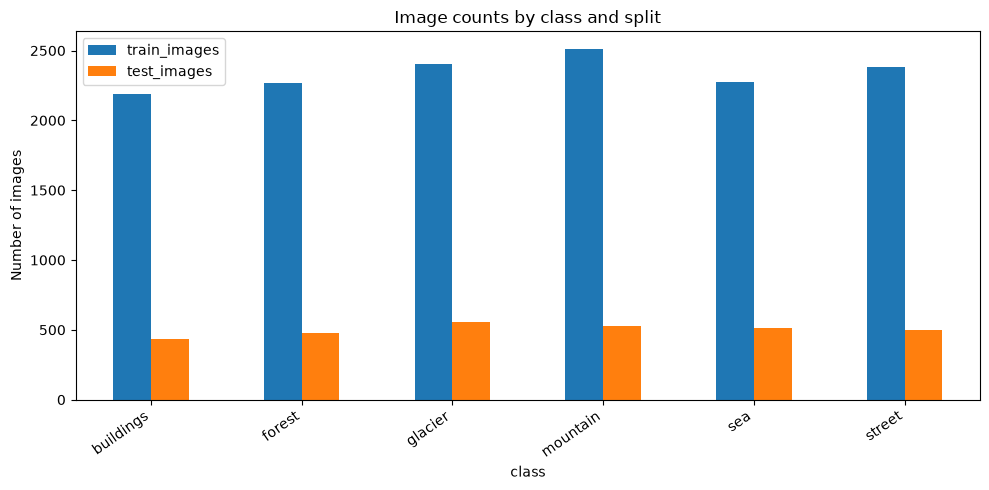

In [4]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
class_names = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])
print("Classes:", class_names)

def image_files(folder):
    return [p for p in pathlib.Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]

train_paths = {c: image_files(TRAIN_DIR / c) for c in class_names}
test_classes = sorted([p.name for p in TEST_DIR.iterdir() if p.is_dir()])
test_paths = {c: image_files(TEST_DIR / c) for c in test_classes}
count_df = pd.DataFrame({
    "class": class_names,
    "train_images": [len(train_paths[c]) for c in class_names],
    "test_images": [len(test_paths.get(c, [])) for c in class_names]
})
display(count_df)
ax = count_df.set_index("class")[["train_images","test_images"]].plot(kind="bar", figsize=(10,5))
ax.set_title("Image counts by class and split"); ax.set_ylabel("Number of images")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

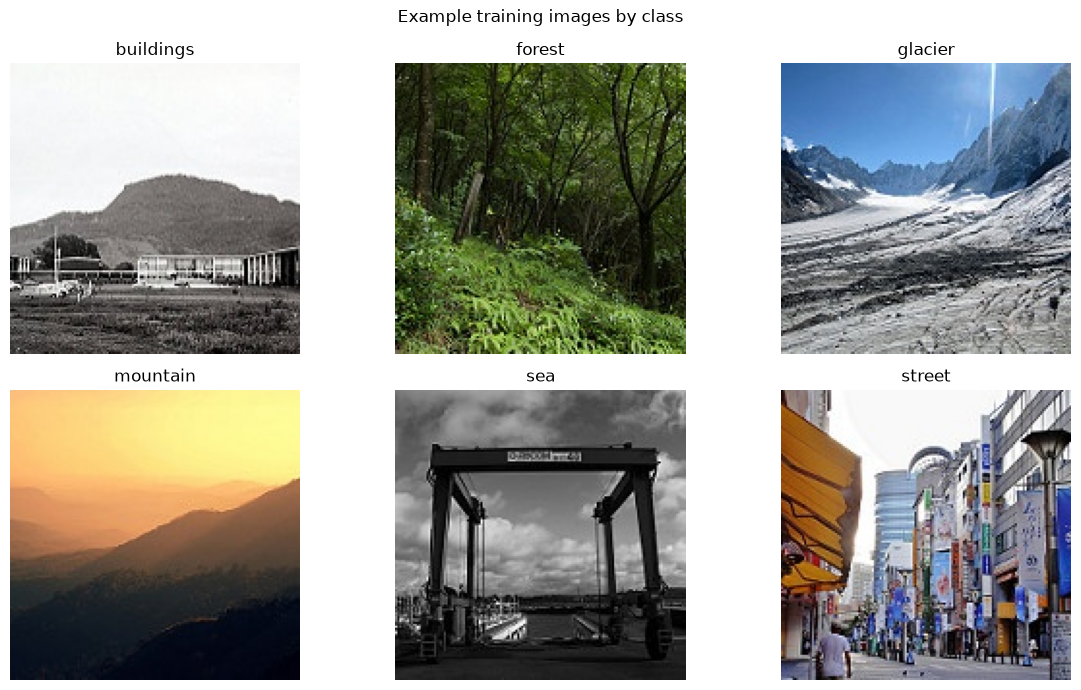

In [5]:
# Sample image grid: one example from each class.
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, cls in zip(axes.ravel(), class_names):
    paths = train_paths[cls]
    if paths:
        with Image.open(paths[0]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Example training images by class"); plt.tight_layout(); plt.show()

Readable training images: 14034
Unreadable/corrupt training images: 0


,images,median_width,median_height,modes
class,,,,
buildings,2191,150.0,150.0,RGB
forest,2271,150.0,150.0,RGB
glacier,2404,150.0,150.0,RGB
mountain,2512,150.0,150.0,RGB
sea,2274,150.0,150.0,RGB
street,2382,150.0,150.0,RGB


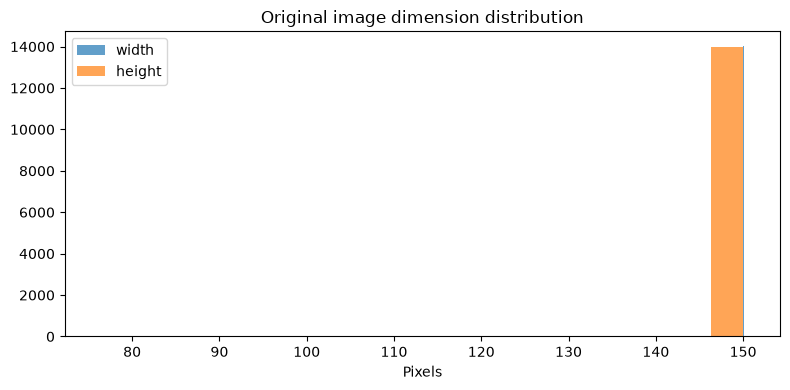

In [16]:
# Audit image dimensions, colour modes and unreadable files.
audit_rows, bad_files = [], []
for cls in class_names:
    for p in train_paths[cls]:
        try:
            with Image.open(p) as im:
                audit_rows.append({
                    "class": cls, "width": im.width, "height": im.height,
                    "mode": im.mode, "format": im.format
                })
                im.verify()
        except Exception:
            bad_files.append(str(p))
audit = pd.DataFrame(audit_rows)
print("Readable training images:", len(audit))
print("Unreadable/corrupt training images:", len(bad_files))
display(audit.groupby("class").agg(
    images=("class","size"), median_width=("width","median"),
    median_height=("height","median"), modes=("mode",lambda x: ", ".join(sorted(set(x))))
))
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(audit["width"], bins=20, alpha=.7, label="width")
ax.hist(audit["height"], bins=20, alpha=.7, label="height")
ax.set_title("Original image dimension distribution"); ax.set_xlabel("Pixels"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Cleaning and data pipeline

Images are decoded as RGB, resized to 150×150 and converted to floating-point tensors. Pixel values are rescaled to [0, 1]. The official test directory is kept separate. A validation split is taken from the training directory. Augmentation is applied only to training batches, never to validation or test images.

In [7]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="int",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=0.20, subset="training", seed=SEED,
    shuffle=True
)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="int",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=0.20, subset="validation", seed=SEED,
    shuffle=False
)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="int",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False
)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Class order:", class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Class order: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## 7. Feature learning and CNN design

For image data, conventional forward/backward feature elimination and P-values are generally unsuitable: individual pixels are high-dimensional, spatially dependent inputs. Instead, convolutional filters learn local visual features (edges, textures and shapes), pooling reduces spatial size, and dense layers combine learned representations for classification.

The custom CNN below uses three convolution blocks, batch normalisation, max pooling, dropout and a six-unit softmax output. Data augmentation is used to improve robustness to modest changes in orientation and framing.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="training_augmentation")

def build_cnn(dropout_rate=0.35, learning_rate=0.001):
    inputs = keras.Input(shape=(150, 150, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_cnn()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 150, 150, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,430 (435.27 KB)

 Trainable params: 110,982 (433.52 KB)

 Non-trainable params: 448 (1.75 KB)

## 8. Train the baseline model

Early stopping monitors validation loss and restores the best weights. Model checkpointing preserves the best validation model. The maximum epoch count is a limit, not a guarantee that all epochs will run.

In [9]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "best_cnn_model.keras", monitor="val_loss",
        save_best_only=True
    )
]
history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=20, callbacks=callbacks
)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 348s 955ms/step - accuracy: 0.5890 - loss: 1.0503 - val_accuracy: 0.2395 - val_loss: 1.9500
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 331s 944ms/step - accuracy: 0.6801 - loss: 0.8400 - val_accuracy: 0.3603 - val_loss: 1.5131
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 313s 891ms/step - accuracy: 0.7414 - loss: 0.7098 - val_accuracy: 0.5167 - val_loss: 1.1322
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 303s 862ms/step - accuracy: 0.7686 - loss: 0.6329 - val_accuracy: 0.6561 - val_loss: 0.9605
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 303s 863ms/step - accuracy: 0.7923 - loss: 0.5797 - val_accuracy: 0.7145 - val_loss: 0.6900
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 339s 966ms/step - accuracy: 0.8026 - loss: 0.5470 - val_accuracy: 0.4833 - val_loss: 1.0092
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 371s 1s/step - accuracy: 0.8151 - loss: 0.5117 - val_accuracy: 0.3831 - val_loss: 1.8448
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 375s 1s/step - accuracy: 0.8213 - loss:

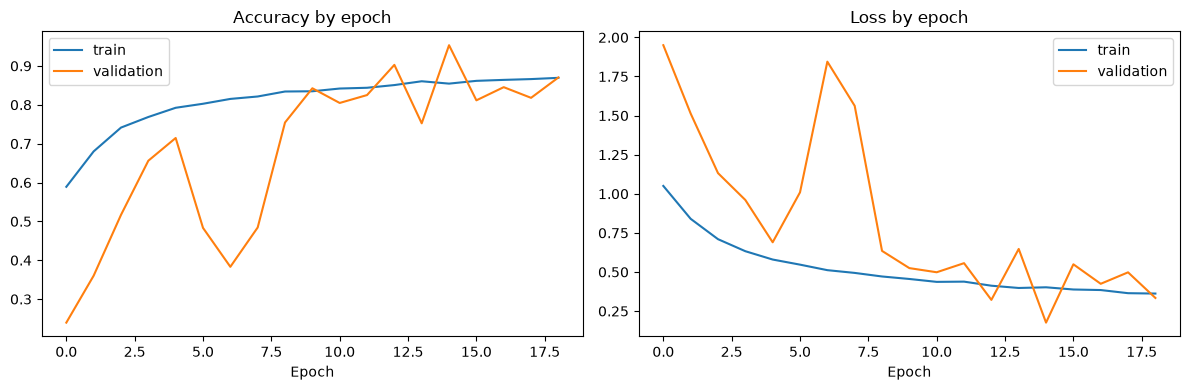

In [10]:
# Plot learning curves to identify underfitting or overfitting.
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(hist["accuracy"], label="train")
axes[0].plot(hist["val_accuracy"], label="validation")
axes[0].set_title("Accuracy by epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist["loss"], label="train")
axes[1].plot(hist["val_loss"], label="validation")
axes[1].set_title("Loss by epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Final evaluation on the held-out test set

Accuracy gives overall correctness, while precision, recall and F1-score reveal class-specific performance. Macro-F1 gives each class equal weight and is useful if class counts differ. The confusion matrix shows which scene types are commonly confused. The test set is used only after model choices have been made on validation data.

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = model.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Test loss: 0.5037
Test accuracy: 0.8123
              precision    recall  f1-score   support

   buildings     0.8657    0.6934    0.7700       437
      forest     0.9770    0.8966    0.9351       474
     glacier     0.9130    0.5696    0.7016       553
    mountain     0.7036    0.8819    0.7828       525
         sea     0.8170    0.8843    0.8493       510
      street     0.7273    0.9581    0.8269       501

    accuracy                         0.8123      3000
   macro avg     0.8340    0.8140    0.8109      3000
weighted avg     0.8323    0.8123    0.8087      3000



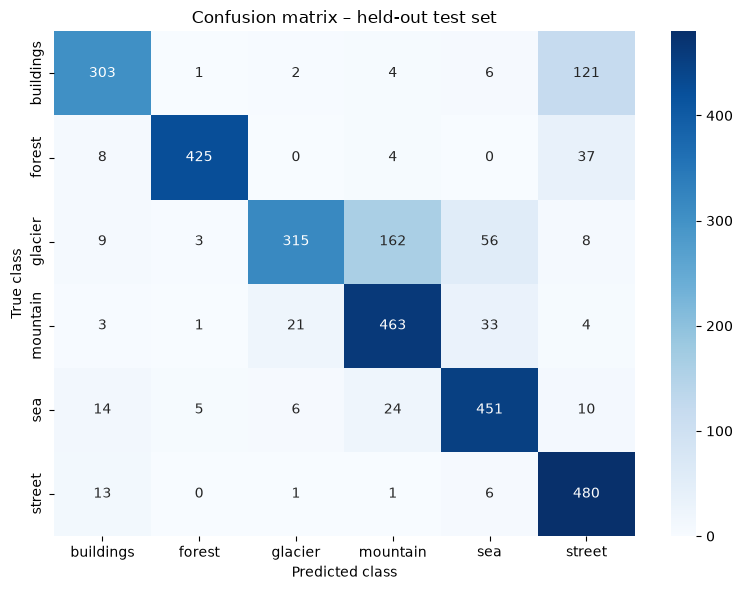

In [12]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class"); plt.ylabel("True class")
plt.title("Confusion matrix – held-out test set")
plt.tight_layout(); plt.show()

Misclassified images: 563 of 3000


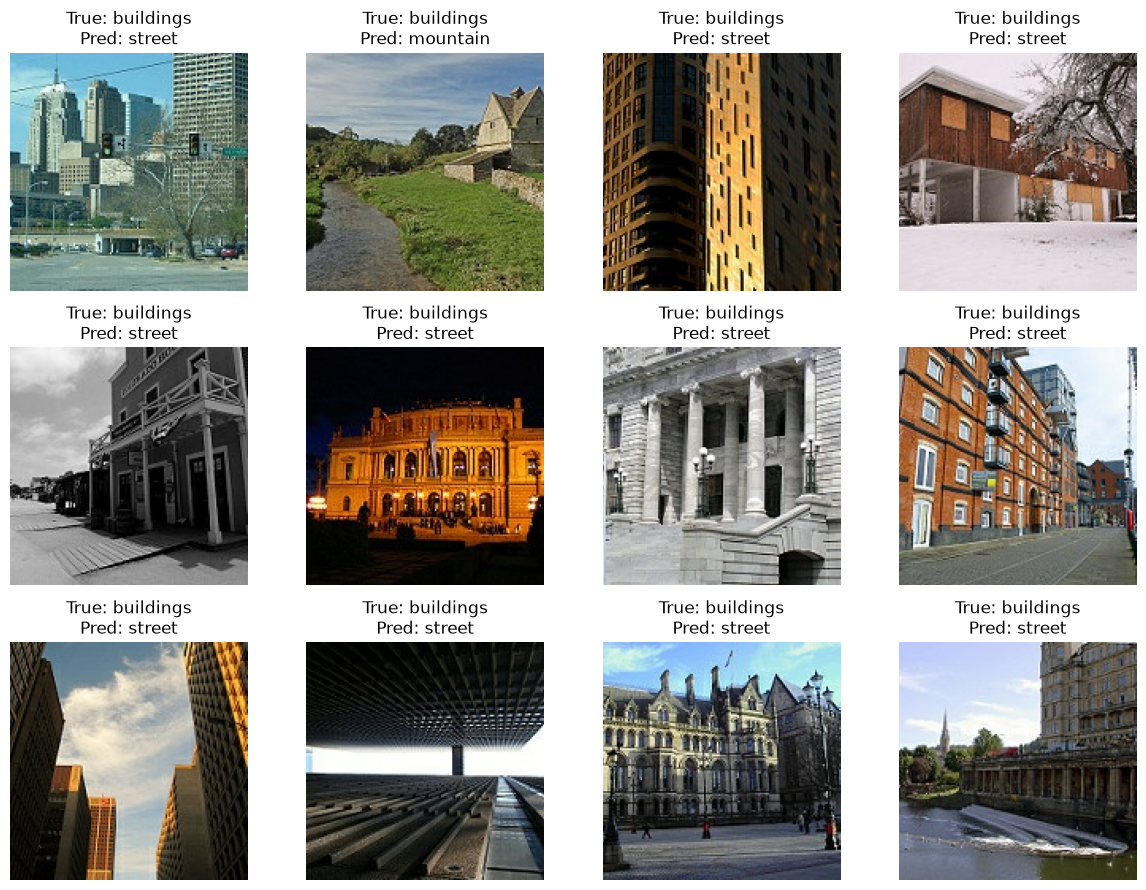

In [13]:
# Show selected incorrect predictions to understand model weaknesses.
test_images = np.concatenate([x.numpy() for x, _ in test_ds])
wrong = np.where(y_true != y_pred)[0]
print("Misclassified images:", len(wrong), "of", len(y_true))
if len(wrong):
    chosen = wrong[:12]
    fig, axes = plt.subplots(3, 4, figsize=(12,9))
    for ax, idx in zip(axes.ravel(), chosen):
        ax.imshow(test_images[idx].astype("uint8"))
        ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 10. Retraining / improvement experiment

This second model increases dropout and lowers the learning rate. It is compared using validation accuracy and validation loss. Select the better model based on validation performance, not by repeatedly tuning against the test set. After selecting a model, evaluate the selected model on the test set once for the final reported result.

In [14]:
improved_model = build_cnn(dropout_rate=0.50, learning_rate=0.0005)
improved_history = improved_model.fit(
    train_ds, validation_data=val_ds, epochs=20,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint("improved_cnn_model.keras",
                                         monitor="val_loss", save_best_only=True)
    ]
)
base_best = min(history.history["val_loss"])
improved_best = min(improved_history.history["val_loss"])
print("Baseline best validation loss:", round(base_best, 4))
print("Improved best validation loss:", round(improved_best, 4))

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.5468 - loss: 1.1451 - val_accuracy: 0.1636 - val_loss: 2.6385
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 325s 925ms/step - accuracy: 0.6574 - loss: 0.9119 - val_accuracy: 0.7384 - val_loss: 0.8320
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 327s 931ms/step - accuracy: 0.6930 - loss: 0.8095 - val_accuracy: 0.3403 - val_loss: 1.7885
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 328s 935ms/step - accuracy: 0.7401 - loss: 0.7110 - val_accuracy: 0.7890 - val_loss: 0.5775
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 314s 894ms/step - accuracy: 0.7621 - loss: 0.6532 - val_accuracy: 0.6486 - val_loss: 0.8086
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 311s 886ms/step - accuracy: 0.7797 - loss: 0.6134 - val_accuracy: 0.7862 - val_loss: 0.5556
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 319s 908ms/step - accuracy: 0.7944 - loss: 0.5760 - val_accuracy: 0.6743 - val_loss: 0.8473
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 311s 887ms/step - accuracy: 0.8026 - lo

In [15]:
# Choose the model with lower best validation loss, then evaluate on test data.
selected_model = improved_model if improved_best < base_best else model
selected_loss, selected_accuracy = selected_model.evaluate(test_ds, verbose=0)
selected_probs = selected_model.predict(test_ds, verbose=0)
selected_pred = np.argmax(selected_probs, axis=1)
print("Selected model:", "improved" if selected_model is improved_model else "baseline")
print(f"Selected test accuracy: {selected_accuracy:.4f}")
print(classification_report(y_true, selected_pred, target_names=class_names, digits=4))
selected_model.save("intel_scene_cnn_final.keras")

Selected model: baseline
Selected test accuracy: 0.8123
              precision    recall  f1-score   support

   buildings     0.8657    0.6934    0.7700       437
      forest     0.9770    0.8966    0.9351       474
     glacier     0.9130    0.5696    0.7016       553
    mountain     0.7036    0.8819    0.7828       525
         sea     0.8170    0.8843    0.8493       510
      street     0.7273    0.9581    0.8269       501

    accuracy                         0.8123      3000
   macro avg     0.8340    0.8140    0.8109      3000
weighted avg     0.8323    0.8123    0.8087      3000



## 11. Interpretation, limitations and conclusion

When execution is complete, report the actual printed test metrics and figures. Do not insert assumed or previously published accuracy as if it were produced by this run.

Discuss: (1) overall test accuracy and macro-F1; (2) classes with low recall; (3) strongest confusions in the confusion matrix; (4) train/validation learning curves; (5) whether the second model improved validation loss and test results; and (6) remaining errors and possible causes.

**Limitations:** the dataset classifies scenes, not people. It does not support facial recognition, identity verification or access-control decisions. A real publisher deployment would require a purpose-built, consented, representative face dataset, demographic and environmental bias testing, privacy/legal review, liveness/anti-spoofing controls, secure storage, human oversight and a rigorous security assessment. Scene-classification accuracy cannot be transferred to facial recognition.

